# Steam Game Success Prediction: Feature Engineering, Model Training & Evaluation

## Overview
This notebook covers the complete machine learning pipeline for predicting the commercial success tier of Steam games (`Low`, `Medium`, `High`). 

### Key Pipeline Stages:
1. **Data Splitting:** Stratified train/validation/test partitioning (60% / 20% / 20%) to prevent data leakage and preserve target class proportions.
2. **Feature Encoding & NLP:** Multi-label binarization with dimensionality control (`top_k`), cross-validated target encoding for developers and publishers, and TF-IDF vectorization for game descriptions.
3. **Model Training & Hyperparameter Tuning:** Training and optimizing three distinct architectures—**Logistic Regression**, **Random Forest**, and **XGBoost**—using `RandomizedSearchCV` and Bayesian optimization (**Optuna**) with class imbalance handling.
4. **Model Evaluation & Comparison:** Assessing validation performance via Macro F1-score, Multiclass ROC AUC (OvR), and confusion matrices.
5. **Final Testing & Interpretability:** Evaluating the best-performing model on the unseen test set and analyzing key predictive drivers through feature importance.


## 1. Data Loading & Initial Setup

This section imports essential data manipulation and visualization libraries, loads the preprocessed Steam dataset and defines global constants (`RANDOM_STATE` and `N_JOBS`) to ensure full reproducibility across experiments.

In [73]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [74]:
df = pd.read_json("../data/processed/steam_games_processed_v2.json")
df.head()

,required_age,price,short_description,windows,mac,linux,achievements,supported_languages,full_audio_languages,developers,...,categories,genres,release_year,release_month,target_num,screenshots_count,has_header_image,has_website,has_support_url,has_support_email
0,0,8.99,Yuha! I'll start the broadcast! Hakko's extrem...,1,0,0,19,[Korean],[Korean],[유진게임즈],...,"[Single-player, Steam Achievements, Family Sha...","[Casual, Indie, Simulation]",2024,10,0,7,1,0,0,1
1,0,13.99,Agony VR is a first-person survival horror gam...,1,0,0,0,"[Turkish, Spanish - Spain, French, Russian, Po...","[Turkish, English]",[Ignibit],...,"[Single-player, Tracked Controller Support, VR...","[Action, Adventure]",2023,4,0,5,1,0,1,1
2,0,0.99,Hepta Beats is a 2D side-view platformer game ...,1,0,0,9,"[Simplified Chinese, Traditional Chinese, Port...","[Simplified Chinese, Traditional Chinese, Port...",[Matheus Bigatão],...,"[Single-player, Steam Achievements, Full contr...","[Casual, Indie]",2021,5,0,7,1,0,0,1
3,0,0.59,Your task in MUMBA IV is to destroy coloured j...,1,1,1,100,"[Simplified Chinese, Traditional Chinese, Port...",[],[Airem],...,"[Single-player, Steam Achievements, Full contr...","[Action, Casual, Indie, Strategy]",2021,12,0,13,1,1,1,1
4,0,1.49,"Forests, Fields and Fortresses - is a mix of a...",1,1,0,13,"[Russian, English]",[],[9 Eyes Game Studio],...,"[Single-player, Steam Achievements, Partial Co...","[Casual, Indie]",2023,4,0,7,1,1,1,1


In [75]:
RANDOM_STATE = 42
N_JOBS = -1

In [76]:
def compute_entity_history(
    df_all: pd.DataFrame, col: str, prefix: str
) -> pd.DataFrame:
    ym = (
        df_all["release_year"].fillna(0).astype(int) * 100
        + df_all["release_month"].fillna(1).astype(int)
    )
    work = pd.DataFrame(
        {
            "_row_id": np.arange(len(df_all)),
            "ym": ym.to_numpy(),
            col: df_all[col].to_numpy(),
            "is_20k": (df_all["target_num"].to_numpy() >= 1).astype(int),
            "is_high": (df_all["target_num"].to_numpy() == 2).astype(int),
        }
    )

    exploded = work.explode(col)
    exploded[col] = exploded[col].fillna("").astype(str).str.strip().str.lower()
    exploded = exploded[exploded[col] != ""]

    # Aggregate by (entity, year-month) to prevent same-month leakage
    monthly = (
        exploded.groupby([col, "ym"], as_index=False)
        .agg(
            m_games=("_row_id", "count"),
            m_20k=("is_20k", "sum"),
            m_high=("is_high", "sum"),
        )
        .sort_values([col, "ym"])
    )

    # Strictly prior stats: cumulative sum minus current month
    g = monthly.groupby(col)
    monthly["prev_games"] = g["m_games"].cumsum() - monthly["m_games"]
    monthly["prev_20k"] = g["m_20k"].cumsum() - monthly["m_20k"]
    monthly["prev_high"] = g["m_high"].cumsum() - monthly["m_high"]

    monthly["prev_20k_rate"] = np.where(
        monthly["prev_games"] > 0, monthly["prev_20k"] / monthly["prev_games"], np.nan
    )
    monthly["prev_high_rate"] = np.where(
        monthly["prev_games"] > 0, monthly["prev_high"] / monthly["prev_games"], np.nan
    )

    merged = exploded[["_row_id", col, "ym"]].merge(
        monthly[
            [
                col,
                "ym",
                "prev_games",
                "prev_20k",
                "prev_high",
                "prev_20k_rate",
                "prev_high_rate",
            ]
        ],
        on=[col, "ym"],
        how="left",
    )

    per_game = (
        merged.groupby("_row_id")
        .agg(
            prev_games=("prev_games", "max"),
            prev_20k_count=("prev_20k", "max"),
            prev_high_count=("prev_high", "max"),
            prev_20k_rate=("prev_20k_rate", "max"),
            prev_high_rate=("prev_high_rate", "max"),
        )
        .reindex(np.arange(len(df_all)))
    )

    out = pd.DataFrame(index=df_all.index)
    out[f"{prefix}_prev_games"] = per_game["prev_games"].fillna(0).astype(int).to_numpy()
    out[f"{prefix}_prev_20k_count"] = per_game["prev_20k_count"].fillna(0).astype(int).to_numpy()
    out[f"{prefix}_prev_high_count"] = per_game["prev_high_count"].fillna(0).astype(int).to_numpy()
    out[f"{prefix}_prev_20k_rate"] = per_game["prev_20k_rate"].to_numpy()
    out[f"{prefix}_prev_high_rate"] = per_game["prev_high_rate"].to_numpy()
    return out


print(
    f"Full df: {len(df)} rows | Years: {df['release_year'].min()} - {df['release_year'].max()}"
)

dev_hist = compute_entity_history(df, "developers", "dev")
pub_hist = compute_entity_history(df, "publishers", "pub")

for hist_df in [dev_hist, pub_hist]:
    for col_name in hist_df.columns:
        df[col_name] = hist_df[col_name]

Full df: 46947 rows | Years: 2021 - 2024


## 2. Dataset Splitting

The dataset is partitioned into training (60%), validation (20%), and test (20%) subsets using stratified sampling to maintain identical target class proportions (`Low`, `Medium`, `High`) across all splits. Indices are reset to ensure clean alignment during subsequent feature concatenation, and the target variable (`target_num`) is isolated into separate vectors to prevent data leakage.

In [77]:
df_train = df[df["release_year"].isin([2021, 2022])].reset_index(drop=True)
df_val = df[df["release_year"] == 2023].reset_index(drop=True)
df_test = df[df["release_year"] == 2024].reset_index(drop=True)

y_train = df_train["target_num"].copy()
y_val = df_val["target_num"].copy()
y_test = df_test["target_num"].copy()

train_years = df_train["release_year"].copy()

df_train = df_train.drop(columns=["target_num", "release_year"])
df_val = df_val.drop(columns=["target_num", "release_year"])
df_test = df_test.drop(columns=["target_num", "release_year"])

print(f"Train (2021-2022): {len(df_train)}")
print(f"Val   (2023):      {len(df_val)}")
print(f"Test  (2024):      {len(df_test)}")

Train (2021-2022): 19717
Val   (2023):      11675
Test  (2024):      15555


## 3. Feature Engineering & Encoding

Raw categorical, multi-label, and textual attributes are transformed into a unified numerical feature matrix. All encoders and vectorizers are fitted strictly on the training set (`df_train`) to prevent data leakage into validation and test subsets.

### 3.1. Primary Entity Extraction & Text Cleaning
Primary developers and publishers are extracted from list columns, while missing values in game descriptions are imputed with empty strings prior to vectorization.

In [78]:
for df_ in [df_train, df_val, df_test]:
    df_["primary_developer"] = df_["developers"].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unknown"
    )
    df_["primary_publisher"] = df_["publishers"].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unknown"
    )

    df_["short_description"] = df_["short_description"].fillna("").astype(str)

### 3.2. Multi-Label Binarization
Multi-value list features (`genres`, `categories`, `tags`, and language support) are converted into binary indicator columns using `MultiLabelBinarizer`. Dimensionality is controlled by restricting high-cardinality features to the most frequent classes based on training counts (`top_k=100` for tags and `top_k=30` for languages) to mitigate overfitting on sparse noise.

In [79]:
from sklearn.preprocessing import MultiLabelBinarizer


def encode_multilabel_feature(
    train_series, val_series, test_series, prefix, top_k=None
):
    train, val, test = train_series.copy(), val_series.copy(), test_series.copy()

    if top_k:
        counts = train.explode().value_counts()
        top_classes = set(counts.head(top_k).index)
        train = train.apply(
            lambda items: (
                [x for x in items if x in top_classes]
                if isinstance(items, list)
                else []
            )
        )
        val = val.apply(
            lambda items: (
                [x for x in items if x in top_classes]
                if isinstance(items, list)
                else []
            )
        )
        test = test.apply(
            lambda items: (
                [x for x in items if x in top_classes]
                if isinstance(items, list)
                else []
            )
        )

    mlb = MultiLabelBinarizer()
    train_raw = mlb.fit_transform(train)
    cols = [f"{prefix}_{c}" for c in mlb.classes_]

    train_encoded = pd.DataFrame(train_raw, columns=cols)
    val_encoded = pd.DataFrame(mlb.transform(val), columns=cols)
    test_encoded = pd.DataFrame(mlb.transform(test), columns=cols)

    return train_encoded, val_encoded, test_encoded

In [80]:
genres_train, genres_val, genres_test = encode_multilabel_feature(
    df_train["genres"], df_val["genres"], df_test["genres"], "genre"
)

cats_train, cats_val, cats_test = encode_multilabel_feature(
    df_train["categories"], df_val["categories"], df_test["categories"], "cat"
)

audio_langs_train, audio_langs_val, audio_langs_test = encode_multilabel_feature(
    df_train["full_audio_languages"],
    df_val["full_audio_languages"],
    df_test["full_audio_languages"],
    "audio_lang",
    top_k=30,
)

langs_train, langs_val, langs_test = encode_multilabel_feature(
    df_train["supported_languages"],
    df_val["supported_languages"],
    df_test["supported_languages"],
    "lang",
    top_k=30,
)

/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:1016: UserWarning: unknown class(es) ['Gamepad Recommended'] will be ignored
  warnings.warn(


### 3.3. Cross-Validated Target Encoding
High-cardinality nominal features (`primary_developer` and `primary_publisher`) are encoded using `sklearn`'s `TargetEncoder` with internal 5-fold cross-validation (`cv=5`) and automatic smoothing. This generates out-of-fold class probability estimates for each target tier without target leakage.


In [81]:
from sklearn.preprocessing import TargetEncoder

te_safe = TargetEncoder(smooth="auto", cv=5, random_state=RANDOM_STATE)

dev_pub_train = pd.DataFrame(
    te_safe.fit_transform(
        df_train[["primary_developer", "primary_publisher"]], y_train
    ),
    columns=te_safe.get_feature_names_out(["primary_developer", "primary_publisher"]),
)
dev_pub_val = pd.DataFrame(
    te_safe.transform(df_val[["primary_developer", "primary_publisher"]]),
    columns=dev_pub_train.columns,
)
dev_pub_test = pd.DataFrame(
    te_safe.transform(df_test[["primary_developer", "primary_publisher"]]),
    columns=dev_pub_train.columns,
)

/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


### 3.4. Text Vectorization (TF-IDF)
Game short descriptions are vectorized into a 300-feature TF-IDF matrix (`max_features=300`) with English stop-word removal to capture key thematic and gameplay keywords.

In [82]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=300, stop_words="english")

tfidf.fit(df_train["short_description"])

tfidf_cols = [f"tfidf_{w}" for w in tfidf.get_feature_names_out()]

tfidf_train = pd.DataFrame(
    tfidf.transform(df_train["short_description"]).toarray(), columns=tfidf_cols
)
tfidf_val = pd.DataFrame(
    tfidf.transform(df_val["short_description"]).toarray(), columns=tfidf_cols
)
tfidf_test = pd.DataFrame(
    tfidf.transform(df_test["short_description"]).toarray(), columns=tfidf_cols
)

### 3.5. Feature Matrix Concatenation
Engineered numerical, binary, target-encoded, and TF-IDF representations are concatenated horizontally into final feature matrices (`X_train_final`, `X_val_final`, `X_test_final`) with verified dimensional alignment.

In [83]:
base_features = [
    "required_age",
    "price",
    "windows",
    "mac",
    "linux",
    "achievements",
    "release_month",
    "screenshots_count",
    "has_header_image",
    "has_website",
    "has_support_url",
    "has_support_email",
    "dev_prev_games",
    "dev_prev_20k_count",
    "dev_prev_high_count",
    "dev_prev_20k_rate",
    "dev_prev_high_rate",
    "pub_prev_games",
    "pub_prev_20k_count",
    "pub_prev_high_count",
    "pub_prev_20k_rate",
    "pub_prev_high_rate",
]

X_train_final = pd.concat(
    [
        df_train[base_features],
        genres_train,
        cats_train,
        audio_langs_train,
        langs_train,
        dev_pub_train,
        tfidf_train,
    ],
    axis=1,
)

X_val_final = pd.concat(
    [
        df_val[base_features],
        genres_val,
        cats_val,
        audio_langs_val,
        langs_val,
        dev_pub_val,
        tfidf_val,
    ],
    axis=1,
)

X_test_final = pd.concat(
    [
        df_test[base_features],
        genres_test,
        cats_test,
        audio_langs_test,
        langs_test,
        dev_pub_test,
        tfidf_test,
    ],
    axis=1,
)

print(f"Train shape: {X_train_final.shape}")
print(f"Val shape:   {X_val_final.shape}")
print(f"Test shape:  {X_test_final.shape}")

Train shape: (19717, 469)
Val shape:   (11675, 469)
Test shape:  (15555, 469)


## 4. Model Training & Hyperparameter Tuning

Three distinct classification algorithms are trained and tuned using cross-validated search strategies, optimizing specifically for `F1-Macro` to account for class imbalance.

### 4.1. Baseline Model: Logistic Regression

#### Feature Scaling
Continuous numerical features (`price`, `achievements`, `screenshots_count`, `release_month`, `market_competition`, and `required_age`) are standardized using `StandardScaler` fitted strictly on the training subset. Binary and pre-normalized features remain unaltered.


#### Hyperparameter Tuning & Serialization
A multinomial Logistic Regression baseline with `class_weight='balanced'` and the `saga` solver is tuned via `RandomizedSearchCV` (3-fold CV) across regularization strength (`C`) and ElasticNet mixing ratio (`l1_ratio`). The optimal estimator is serialized to disk using `joblib`.

In [84]:
import joblib

#### Evaluation Function & Validation Results
A reusable evaluation utility computes overall Accuracy, Macro F1-score, and One-vs-Rest (OvR) Multiclass ROC AUC, alongside a detailed per-class classification report and confusion matrix heatmap.

In [85]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)


def evaluate_model(model, X_val, y_val, model_name="Model"):
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)

    f1_macro = f1_score(y_val, y_pred, average="macro")
    acc = accuracy_score(y_val, y_pred)
    roc_auc = roc_auc_score(y_val, y_prob, multi_class="ovr", average="macro")

    print(f"=== {model_name} ===")
    print(f"Accuracy:        {acc:.4f}")
    print(f"F1-Score (Macro): {f1_macro:.4f}")
    print(f"ROC AUC (Macro):  {roc_auc:.4f}\n")
    print(classification_report(y_val, y_pred, target_names=["Low", "Medium", "High"]))

    cm = confusion_matrix(y_val, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"],
    )
    plt.title(f"Confusion Matrix: {model_name}")
    plt.ylabel("Actual Tier")
    plt.xlabel("Predicted Tier")
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": acc,
        "F1_Macro": f1_macro,
        "ROC_AUC": roc_auc,
    }

### 4.2. Random Forest Classifier

A `RandomForestClassifier` is trained on the unscaled feature matrix (`X_train_final`) to capture non-linear feature interactions. Hyperparameters—including tree count (`n_estimators`), maximum depth (`max_depth`), minimum leaf size (`min_samples_leaf`), feature subsampling (`max_features`), and class weighting (`balanced_subsample` vs. `None`)—are tuned via 5-fold `RandomizedSearchCV` (`n_iter=15`) optimizing for `F1-Macro`. The optimal estimator is serialized via `joblib` and evaluated on the validation set.

### 4.3. Gradient Boosting: XGBoost Classifier (Bayesian Optimization)

An `XGBClassifier` (`objective='multi:softprob'`, `tree_method='hist'`) is optimized via Bayesian hyperparameter search (**Optuna**, 15 trials, 3-fold CV). To mitigate class imbalance without inducing severe false-positive drift toward minority tiers, square-root-smoothed sample weights (`np.sqrt(compute_sample_weight('balanced', ...))`) are applied during fitting, while an unweighted `make_scorer(f1_score, average='macro')` ensures unbiased cross-validation scoring. Search spaces span tree complexity (`max_depth`, `min_child_weight`), learning dynamics (`n_estimators`, `learning_rate`), stochastic subsampling (`subsample`, `colsample_bytree`), and L1/L2 regularization (`reg_alpha`, `reg_lambda`). The optimal model is serialized natively in JSON format (`best_xgboost.json`) and evaluated on the validation subset.

In [86]:
import optuna
from sklearn.metrics import log_loss, roc_auc_score
from xgboost import XGBClassifier


def objective(trial):
    params = {
        "n_estimators": 1000,
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.15, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 7),
        "min_child_weight": trial.suggest_int("min_child_weight", 5, 40),
        "subsample": trial.suggest_float("subsample", 0.65, 0.95),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.35, 0.85),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 15.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 15.0, log=True),
        "objective": "multi:softprob",
        "num_class": 3,
        "eval_metric": "mlogloss",
        "tree_method": "hist",
        "early_stopping_rounds": 50,
        "random_state": RANDOM_STATE,
        "n_jobs": N_JOBS,
    }

    model = XGBClassifier(**params)
    model.fit(
        X_train_final,
        y_train,
        eval_set=[(X_val_final, y_val)],
        verbose=False,
    )

    val_probs = model.predict_proba(X_val_final)
    return log_loss(y_val, val_probs)


study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)

# Baseline from previous run
study.enqueue_trial(
    {
        "learning_rate": 0.0674297276825242,
        "max_depth": 4,
        "min_child_weight": 11,
        "subsample": 0.9485936919171618,
        "colsample_bytree": 0.6019645132453856,
        "reg_alpha": 9.131567024386403,
        "reg_lambda": 3.57686693575698,
    }
)

study.optimize(objective, n_trials=30)

print(f"\nBest Val LogLoss: {study.best_value:.4f}")
print(f"Best parameters: {study.best_params}")

best_xgb = XGBClassifier(
    **study.best_params,
    n_estimators=1000,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    tree_method="hist",
    early_stopping_rounds=50,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
best_xgb.fit(
    X_train_final,
    y_train,
    eval_set=[(X_val_final, y_val)],
    verbose=False,
)

print(f"Best iteration: {best_xgb.best_iteration}")

for name, X_split, y_split in [
    ("Val (2023)", X_val_final, y_val),
    ("Test (2024)", X_test_final, y_test),
]:
    probs = best_xgb.predict_proba(X_split)
    ll = log_loss(y_split, probs)
    auc = roc_auc_score(y_split, probs, multi_class="ovr", average="macro")
    print(f"{name:12s} | LogLoss: {ll:.4f} | ROC-AUC: {auc:.4f}")

[I 2026-11-23 10:57:48,207] A new study created in memory with name: no-name-279b55c4-142d-4321-8c8e-93485e1c2d6c
[I 2026-11-23 10:58:33,743] Trial 0 finished with value: 0.5119746327400208 and parameters: {'learning_rate': 0.0674297276825242, 'max_depth': 4, 'min_child_weight': 11, 'subsample': 0.9485936919171618, 'colsample_bytree': 0.6019645132453856, 'reg_alpha': 9.131567024386403, 'reg_lambda': 3.57686693575698}. Best is trial 0 with value: 0.5119746327400208.
[I 2026-11-23 10:59:34,445] Trial 1 finished with value: 0.5111880898475647 and parameters: {'learning_rate': 0.03553295925546116, 'max_depth': 7, 'min_child_weight': 31, 'subsample': 0.829597545259111, 'colsample_bytree': 0.42800932022121824, 'reg_alpha': 0.004481747169144631, 'reg_lambda': 0.0017480846733470788}. Best is trial 1 with value: 0.5111880898475647.
[I 2026-11-23 10:59:54,961] Trial 2 finished with value: 0.513310432434082 and parameters: {'learning_rate': 0.11022177607905671, 'max_depth': 6, 'min_child_weight':


Best Val LogLoss: 0.5102
Best parameters: {'learning_rate': 0.018493277707481513, 'max_depth': 7, 'min_child_weight': 8, 'subsample': 0.8061303046919053, 'colsample_bytree': 0.5437713481633702, 'reg_alpha': 3.238199209465676, 'reg_lambda': 0.7609796758482871}
Best iteration: 744
Val (2023)   | LogLoss: 0.5102 | ROC-AUC: 0.7853
Test (2024)  | LogLoss: 0.4668 | ROC-AUC: 0.7715


In [92]:
best_xgb.save_model("best_xgboost_v2.json")

In [93]:
best_xgb = XGBClassifier()
best_xgb.load_model("best_xgboost_v2.json")

=== XGBoost Classifier V2 ===
Accuracy:        0.8159
F1-Score (Macro): 0.5021
ROC AUC (Macro):  0.7853

              precision    recall  f1-score   support

         Low       0.85      0.97      0.90      9401
      Medium       0.40      0.08      0.14      1646
        High       0.49      0.45      0.46       628

    accuracy                           0.82     11675
   macro avg       0.58      0.50      0.50     11675
weighted avg       0.76      0.82      0.77     11675



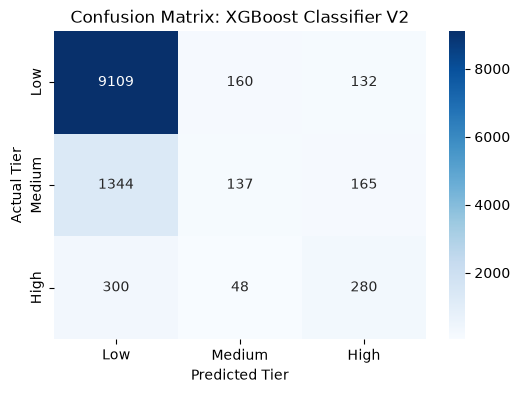

In [94]:
xgb_results = evaluate_model(
    best_xgb, X_val_final, y_val, model_name="XGBoost Classifier V2"
)

## 5. Model Comparison & Final Test Evaluation

### 5.1. Validation Performance Comparison
Validation metrics across all three tuned architectures are aggregated and ranked by `F1-Macro` to select the optimal candidate for final deployment.

### 5.2. Final Hold-Out Test Evaluation
Based on superior validation performance across all target metrics (`F1-Macro: 0.6809`, `ROC AUC: 0.8937`), the tuned **XGBoost Classifier** is selected as the final model and evaluated once on the unseen test set (`X_test_final`) to establish unbiased generalization performance.

=== XGBoost (FINAL TEST) ===
Accuracy:        0.8547
F1-Score (Macro): 0.4869
ROC AUC (Macro):  0.7715

              precision    recall  f1-score   support

         Low       0.89      0.97      0.93     13343
      Medium       0.29      0.07      0.11      1583
        High       0.39      0.45      0.42       629

    accuracy                           0.85     15555
   macro avg       0.53      0.49      0.49     15555
weighted avg       0.81      0.85      0.82     15555



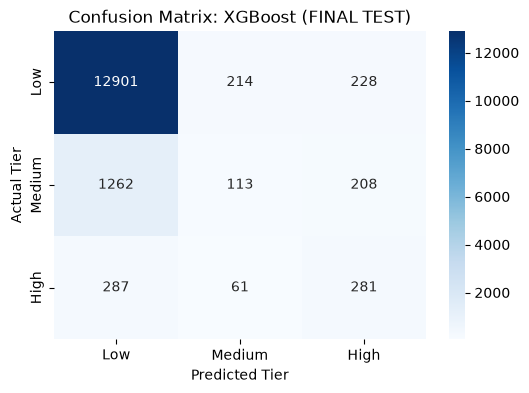

In [95]:
final_test_results = evaluate_model(
    best_xgb, X_test_final, y_test, model_name="XGBoost (FINAL TEST)"
)

## 6. Model Interpretability: Feature Importance Analysis

Gain-based feature importances extracted from the final **XGBoost** model reveal the top 15 primary drivers behind commercial tier predictions. Platform trust signals (`cat_Steam Trading Cards`), multiplayer/free-to-play mechanics, historical publisher performance (`TargetEncoder` probabilities), localization (`lang_French`), and engineered market competition metrics emerge as key predictors.

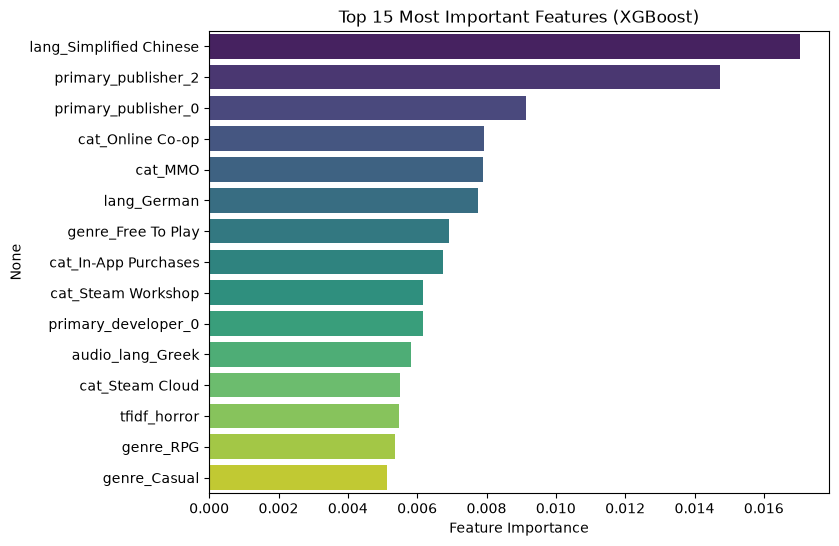

In [96]:
importances = pd.Series(best_xgb.feature_importances_, index=X_train_final.columns)
top_15_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(
    x=top_15_features.values,
    y=top_15_features.index,
    hue=top_15_features.index,
    palette="viridis",
)
plt.title("Top 15 Most Important Features (XGBoost)")
plt.xlabel("Feature Importance")
plt.show()

In [19]:
probs = best_xgb.predict_proba(X_test_final)

# 1. Отдельный ROC-AUC для каждого класса
for i, name in enumerate(["Low", "Medium", "High"]):
    auc_i = roc_auc_score((y_test == i).astype(int), probs[:, i])
    print(f"ROC-AUC ({name:6s}): {auc_i:.4f}")

# 2. Средние предсказанные вероятности внутри каждого реального класса
prob_df = pd.DataFrame(probs, columns=["P(Low)", "P(Medium)", "P(High)"])
prob_df["Actual"] = y_test.map({0: "Low", 1: "Medium", 2: "High"}).values
display(prob_df.groupby("Actual").mean().loc[["Low", "Medium", "High"]].round(4))

ROC-AUC (Low   ): 0.7672
ROC-AUC (Medium): 0.6718
ROC-AUC (High  ): 0.8611


,P(Low),P(Medium),P(High)
Actual,,,
Low,0.7558,0.1909,0.0533
Medium,0.6013,0.2512,0.1475
High,0.3922,0.2389,0.3689
